# The insertions purged in warm gardens: where do they land?

`temporal_s_consolidated.ipynb` shows that in the hot gardens, SVs decline more than SNPs at the
same initial frequency. `sv_insertion_content.ipynb` shows that, in the founder panel, insertions
are 5× depleted in coding sequence. This notebook joins the two: **take the insertions that decline
in warm gardens more than a same-frequency SNP — where do they sit in the genome?**

**Set.** The 2,546 insertions among the 4,946 SVs the temporal arm tests (founder MAC 12–219,
call rate ≥ 0.9, 0.02 ≤ p0 ≤ 0.98). Joined to the landing-site table by panel record ordinal,
not `chrom:pos` (2.14% of positions are multiallelic); verified by corr(seed-mix p0, founder
frequency) = 0.998.

**"Purged more than a same-frequency SNP".** Each insertion's climate slope
`beta(bio1) = d s / d bio1` is placed as a percentile within the `beta` distribution of SNPs in
its p0 bin. Flagged = percentile < 0.10 (purging intensifies with heat more than for 90% of
matched SNPs). 313 of 2,546 (12.3%; 10% expected under a SNP-like null).

In [1]:

import os, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({'figure.dpi':110,'font.size':8,'axes.linewidth':0.6})

G=os.path.abspath(os.path.join(os.getcwd(),"..","r1_sv_negative_selection","results","sv_adaptive"))
os.makedirs(f"{G}/plots",exist_ok=True)
CLS=["CDS","UTR","exon_noncoding","intron","intergenic"]
CCOL={"CDS":"#D55E00","UTR":"#E69F00","exon_noncoding":"#009E73","intron":"#0072B2","intergenic":"0.55"}
FLAG="#B2182B"; REST="0.45"

def style(ax,axis="both"):
    ax.set_axisbelow(True); ax.grid(color="0.88",lw=0.7,axis=axis)
    for sp in ax.spines.values(): sp.set_visible(False)
def pfmt(p): return f"{p:.1e}" if p<1e-3 else f"{p:.3f}"
def stat(ax,txt,loc=(0.03,0.03)):
    ax.annotate(txt,xy=loc,xycoords="axes fraction",fontsize=8.5,color="0.3")

J=pd.read_csv(f"{G}/insertion_landing_vs_purging.csv")
P=json.load(open(f"{G}/insertion_landing_vs_purging.json"))
F,R=J[J.flagA],J[~J.flagA]
ALL=pd.read_csv(f"{G}/insertion_context.csv")
Z=np.load(f"{G}/insertion_context.npz",allow_pickle=True)
gfrac=dict(zip(Z["genome_frac_keys"].astype(str),Z["genome_frac"]))
EXP={"CDS":gfrac["CDS"],"UTR":gfrac["UTR"],
     "intron":max(gfrac["gene"]-gfrac["exon"],0),
     "exon_noncoding":max(gfrac["exon"]-gfrac["CDS"]-gfrac["UTR"],0),
     "intergenic":max(1-gfrac["gene"],0)}
A0=pd.read_csv(f"{G}/insertion_beta_all.csv")          # beta for every insertion, no MAC / p0 filter
SIG=A0[(A0.beta_bio1<0)&(A0.beta_bio1_p<0.05)]
POS=A0[(A0.beta_bio1>0)&(A0.beta_bio1_p<0.05)]
DEL=pd.read_csv(f"{G}/deletion_beta_all.csv")           # every deletion: context + beta; tested/flagA for the MAC>=12 ones
DSIG=DEL[(DEL.beta_bio1<0)&(DEL.beta_bio1_p<0.05)]
DPOS=DEL[(DEL.beta_bio1>0)&(DEL.beta_bio1_p<0.05)]
DF=DEL[DEL.flagA]
print(f"INSERTIONS  {len(ALL):,} in the panel; {len(J):,} tested; purged more than matched SNPs: {len(F)} ({100*len(F)/len(J):.1f}%)")
print(f"  beta(bio1) over {int(A0.n_sites.iloc[0])} sites: < 0 for {100*(A0.beta_bio1<0).mean():.1f}% (null 50%); "
      f"< 0 and p < 0.05: {len(SIG):,} ({100*len(SIG)/len(A0):.1f}%); > 0 and p < 0.05: {len(POS):,} ({100*len(POS)/len(A0):.1f}%); null 2.5% each side")
print(f"DELETIONS   {len(DEL):,} in the panel; {int(DEL.tested.sum())} tested; purged more than matched SNPs: {len(DF)} ({100*len(DF)/DEL.tested.sum():.1f}%)")
print(f"  beta(bio1): < 0 for {100*(DEL.beta_bio1<0).mean():.1f}%; "
      f"< 0 and p < 0.05: {len(DSIG):,} ({100*len(DSIG)/len(DEL):.1f}%); > 0 and p < 0.05: {len(DPOS):,} ({100*len(DPOS)/len(DEL):.1f}%)")

# the SNP reference: beta exists for a 25k SNP subsample only in the MAC>=12 world (no SNP beta below p0=0.02)
ZS=np.load(f"{G}/s_climate_slope.npz"); isdel=ZS["sv_isdel"].astype(bool)
print(f"\nSNP REFERENCE (MAC>=12, 0.02<=p0<=0.98 -- the only range with SNP betas): beta(bio1) < 0 for "
      f"SNPs {100*(ZS['beta_snp_bio1']<0).mean():.1f}% | small indels {100*(ZS['beta_indel_bio1']<0).mean():.1f}% | "
      f"SV insertions {100*(ZS['beta_sv_bio1'][~isdel]<0).mean():.1f}% | SV deletions {100*(ZS['beta_sv_bio1'][isdel]<0).mean():.1f}%")
e=np.quantile(ZS["p0_snp"],np.linspace(0,1,6)); e[-1]+=1e-9
bs=np.digitize(ZS["p0_snp"],e[1:-1]); bi=np.digitize(ZS["p0_sv"][~isdel],e[1:-1]); bd=np.digitize(ZS["p0_sv"][isdel],e[1:-1])
print(f"{'p0 bin':<16}{'SNP':>8}{'insertion':>11}{'deletion':>10}")
for b_ in range(5):
    print(f"[{e[b_]:.3f},{e[b_+1]:.3f}) {100*(ZS['beta_snp_bio1'][bs==b_]<0).mean():>7.1f}%{100*(ZS['beta_sv_bio1'][~isdel][bi==b_]<0).mean():>10.1f}%{100*(ZS['beta_sv_bio1'][isdel][bd==b_]<0).mean():>9.1f}%")


INSERTIONS  172,220 in the panel; 2,546 tested; purged more than matched SNPs: 313 (12.3%)
  beta(bio1) over 31 sites: < 0 for 67.0% (null 50%); < 0 and p < 0.05: 46,708 (27.1%); > 0 and p < 0.05: 11,842 (6.9%); null 2.5% each side
DELETIONS   54,248 in the panel; 2400 tested; purged more than matched SNPs: 243 (10.1%)
  beta(bio1): < 0 for 62.3%; < 0 and p < 0.05: 13,623 (25.1%); > 0 and p < 0.05: 4,751 (8.8%)

SNP REFERENCE (MAC>=12, 0.02<=p0<=0.98 -- the only range with SNP betas): beta(bio1) < 0 for SNPs 54.8% | small indels 55.1% | SV insertions 67.4% | SV deletions 51.9%
p0 bin               SNP  insertion  deletion
[0.020,0.075)    59.9%      73.4%     61.1%
[0.075,0.119)    62.0%      70.7%     61.5%
[0.119,0.206)    58.1%      66.1%     56.4%
[0.206,0.441)    52.9%      55.3%     53.0%
[0.441,0.980)    41.2%      47.7%     38.6%


## 0. Where SVs land: all of them, the ones declining with heat, the ones purged more than SNPs

The opening figure of `sv_insertion_content.ipynb`, repeated for three sets (one per row, named in
the y-axis label), first for insertions and then for deletions. Left: cumulative distribution of
ALT frequency among called founders, by landing class. Right: the share of variants in each class
(coloured) next to the share of the genome that class occupies (grey), with the ratio — 0.19× means
insertions land in CDS at a fifth of the rate the genome's CDS content would predict.

- **Row 1 — every variant** of that type in the founder panel, no MAC floor.
- **Row 2 — climate slope negative and significant, no MAC floor.** `beta(bio1) = d s / d bio1`
  computed for every variant from the per-site `s` the no-filter arm stored (31 gardens, same
  across-site OLS as the production beta); `beta < 0` = declines more the hotter the garden;
  significance is a t-test on the slope over the 31 gardens, p < 0.05. Under no selection 2.5% of
  variants would land here; the matching significantly *positive* set is printed for contrast.
- **Row 3 — purged more than a same-frequency SNP** (MAC ≥ 12 tested set; `beta(bio1)` below the
  10th percentile of p0-matched SNPs — the set used in §1–2).

Row 3's intron excess / non-coding-exon deficit relative to the genome are properties of the
**common-variant survivor set, not of purging** — the unflagged tested insertions are 23.8%
intronic too (§1 makes that comparison directly). What *is* comparable across rows is **CDS**.

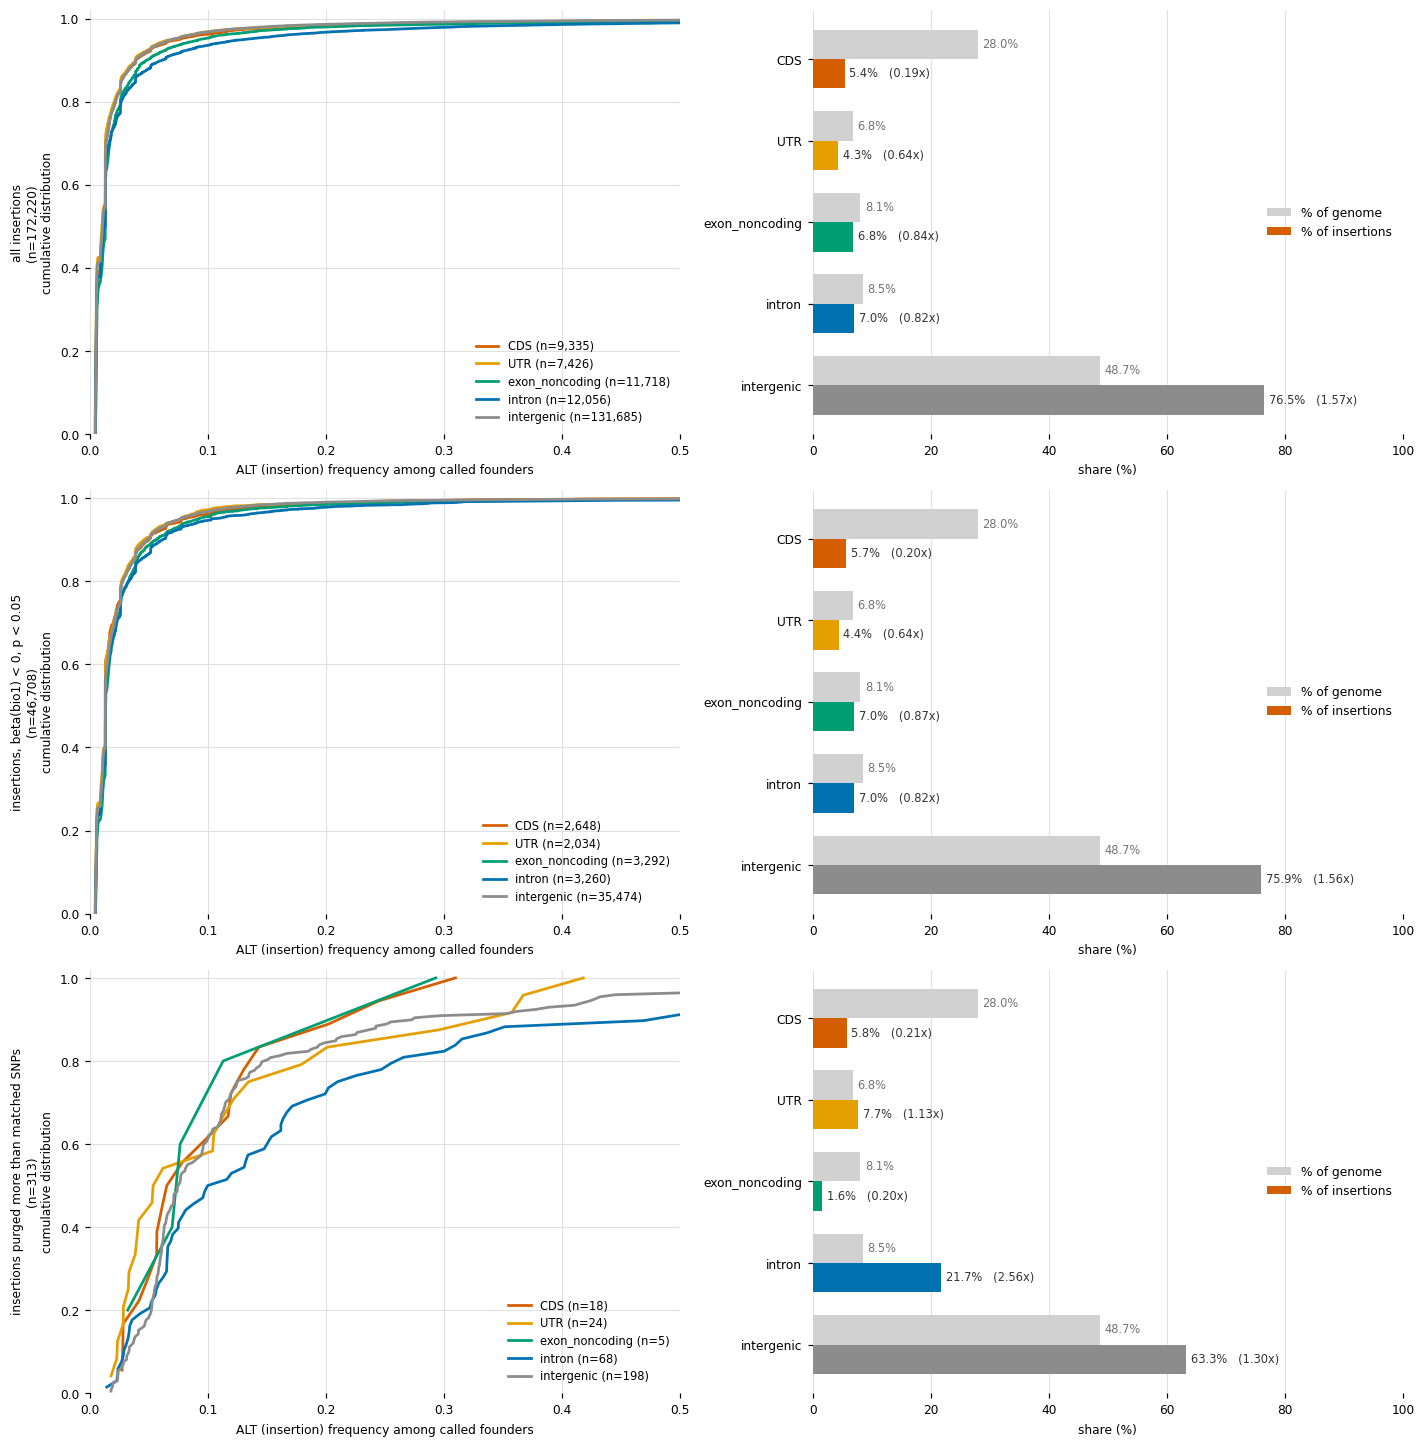

columns: [1] all insertions | [2] insertions, beta(bio1) < 0, p < 0.05 | [3] insertions purged more than matched SNPs
class           genome %         [1] n      %  ratio         [2] n      %  ratio         [3] n      %  ratio
CDS                 28.0         9,335   5.4%  0.19x         2,648   5.7%  0.20x            18   5.8%  0.21x
UTR                  6.8         7,426   4.3%  0.64x         2,034   4.4%  0.64x            24   7.7%  1.13x
exon_noncoding       8.1        11,718   6.8%  0.84x         3,292   7.0%  0.87x             5   1.6%  0.20x
intron               8.5        12,056   7.0%  0.82x         3,260   7.0%  0.82x            68  21.7%  2.56x
intergenic          48.7       131,685  76.5%  1.57x        35,474  75.9%  1.56x           198  63.3%  1.30x


In [2]:

def spectrum_and_share(ax_l,ax_r,D,ylab,kind="insertion"):
    style(ax_l)
    for c in CLS:
        v=np.sort(D.loc[D.genic==c,"freq"].values)
        if v.size==0: continue
        ax_l.plot(v,np.arange(1,v.size+1)/v.size,color=CCOL[c],lw=1.8,label=f"{c} (n={v.size:,})")
    ax_l.set_xlim(0,0.5); ax_l.set_ylim(0,1.02)
    ax_l.set_xlabel("ALT (insertion) frequency among called founders"); ax_l.set_ylabel(ylab)
    ax_l.legend(frameon=False,fontsize=7.5,loc="lower right")
    style(ax_r,axis="x")
    obs=D.genic.value_counts(normalize=True)
    yy=np.arange(len(CLS))[::-1]; h=0.36
    ax_r.barh(yy+h/2,[100*EXP[c] for c in CLS],height=h,color="0.82",linewidth=0,label="% of genome")
    ax_r.barh(yy-h/2,[100*obs.get(c,0) for c in CLS],height=h,color=[CCOL[c] for c in CLS],linewidth=0,label=f"% of {kind}s")
    for y,c in zip(yy,CLS):
        e=100*EXP[c]; o=100*obs.get(c,0)
        ax_r.annotate(f"{e:.1f}%",(e,y+h/2),xytext=(3,0),textcoords="offset points",va="center",fontsize=7.5,color="0.45")
        ax_r.annotate(f"{o:.1f}%   ({o/e:.2f}x)" if e>0 else f"{o:.1f}%",(o,y-h/2),xytext=(3,0),textcoords="offset points",va="center",fontsize=7.5,color="0.2")
    ax_r.set_yticks(yy); ax_r.set_yticklabels(CLS,fontsize=8); ax_r.set_xlim(0,100)
    ax_r.set_xlabel("share (%)"); ax_r.legend(frameon=False,fontsize=8,loc="center right")

def block(sets,kind,fname):
    fig,ax=plt.subplots(len(sets),2,figsize=(13,4.4*len(sets)))
    for i,(D,lab) in enumerate(sets):
        spectrum_and_share(ax[i,0],ax[i,1],D,lab+"\ncumulative distribution",kind)
        ax[i,0].set_xlabel(f"ALT ({kind}) frequency among called founders")
    fig.tight_layout(); fig.savefig(f"{G}/plots/{fname}",dpi=130,bbox_inches="tight"); plt.show()
    print("columns: " + " | ".join(f"[{i+1}] {lab.split(chr(10))[0]}" for i,(_,lab) in enumerate(sets)))
    print(f"{'class':<15}{'genome %':>9}"+"".join(f"{'['+str(i+1)+'] n':>14}{'%':>7}{'ratio':>7}" for i in range(len(sets))))
    for c in CLS:
        line=f"{c:<15}{100*EXP[c]:>9.1f}"
        for D,_ in sets:
            o=(D.genic==c).mean(); line+=f"{(D.genic==c).sum():>14,}{100*o:>6.1f}%{o/EXP[c]:>6.2f}x"
        print(line)

block([(ALL,"all insertions\n(n=%s)"%f"{len(ALL):,}"),
       (SIG,"insertions, beta(bio1) < 0, p < 0.05\n(n=%s)"%f"{len(SIG):,}"),
       (F,"insertions purged more than matched SNPs\n(n=%d)"%len(F))],
      "insertion","ins_spectrum_share_by_set.png")


### The same three rows for deletions

For a deletion the "site" is the removed interval `[pos, pos+ref_len)`, so it is classified by what
it **overlaps** (priority CDS > UTR > non-coding exon > intron; a deletion touching any coding base
is CDS). Two consequences for reading it against the insertion block: overlap probability grows with
length (median 363 bp, p99 31 kb) while the genome-share baseline is point-based, so the ratios run
higher than a point classification would give — the midpoint-based version is printed for
comparison; and `exon_noncoding` for deletions is largely **transposable-element genes** (they have
exons but no CDS in the TAIR10 GFF), i.e. deleted TE copies.

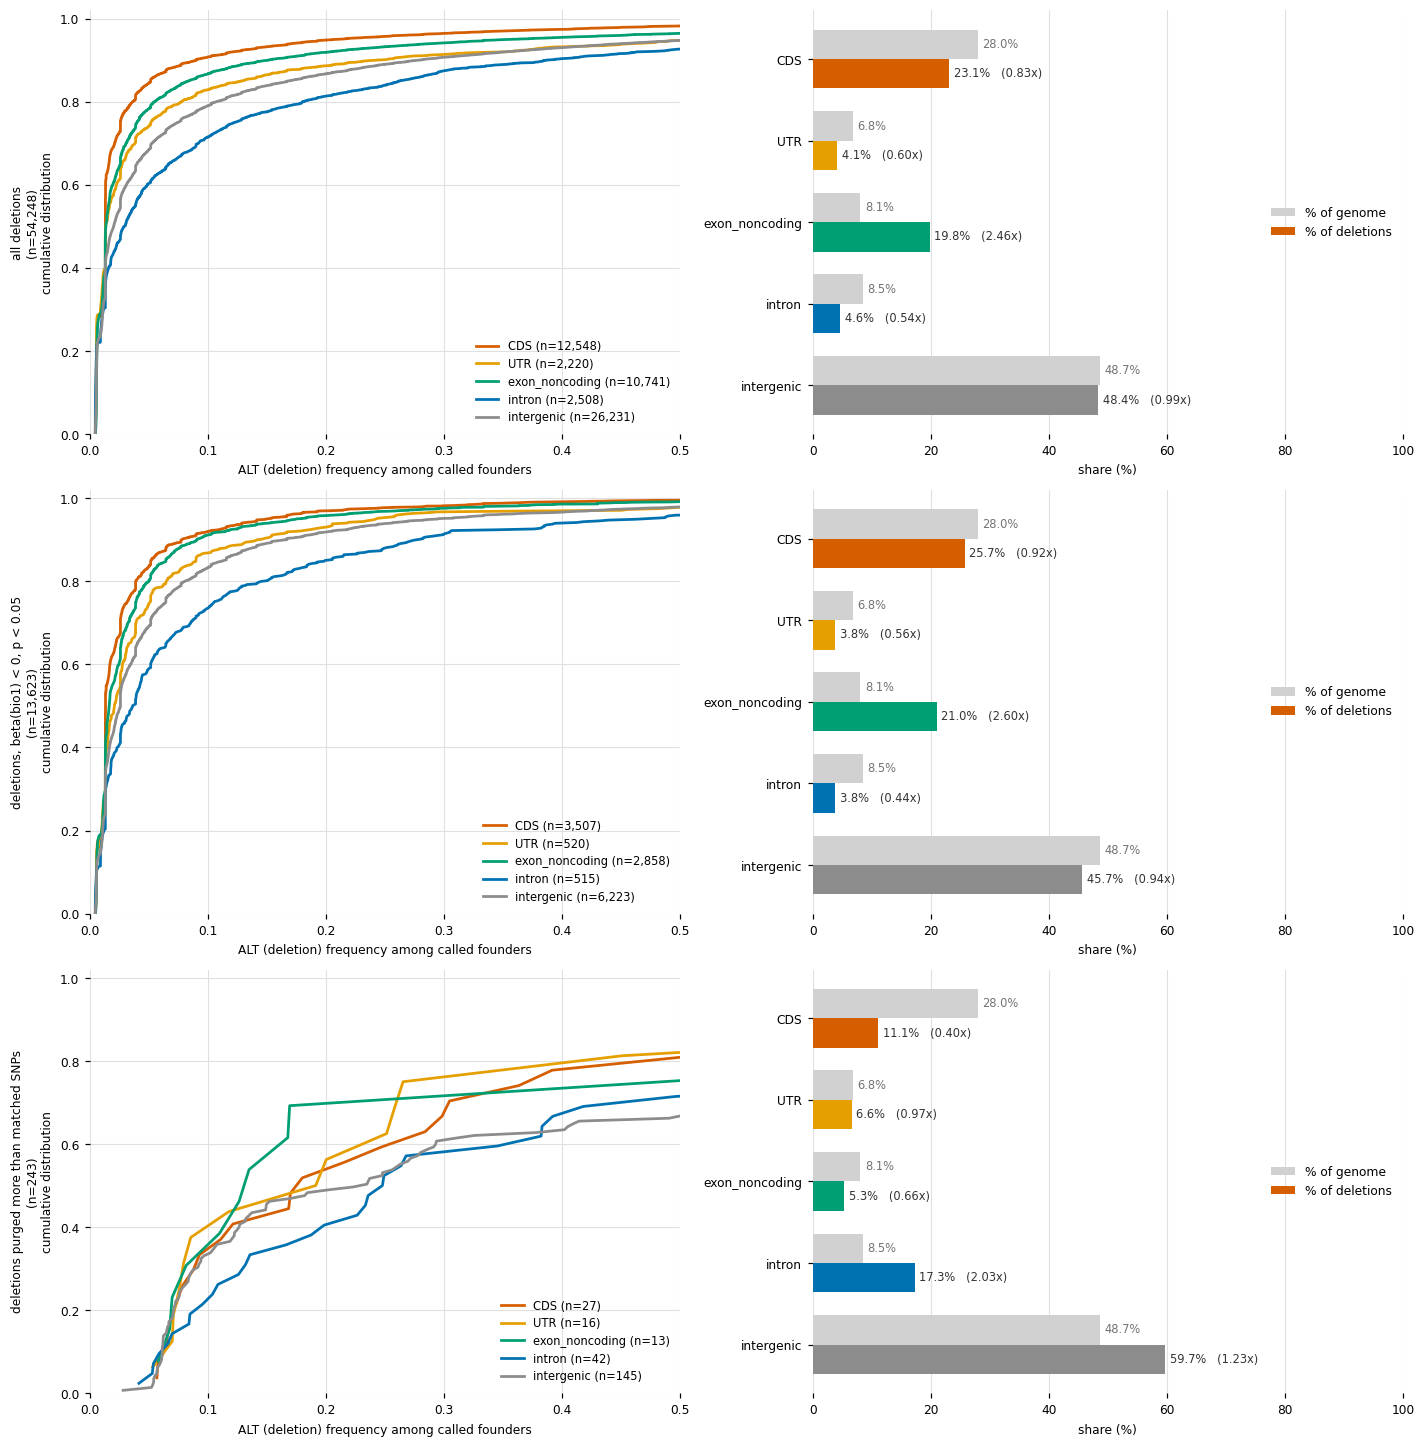

columns: [1] all deletions | [2] deletions, beta(bio1) < 0, p < 0.05 | [3] deletions purged more than matched SNPs
class           genome %         [1] n      %  ratio         [2] n      %  ratio         [3] n      %  ratio
CDS                 28.0        12,548  23.1%  0.83x         3,507  25.7%  0.92x            27  11.1%  0.40x
UTR                  6.8         2,220   4.1%  0.60x           520   3.8%  0.56x            16   6.6%  0.97x
exon_noncoding       8.1        10,741  19.8%  2.46x         2,858  21.0%  2.60x            13   5.3%  0.66x
intron               8.5         2,508   4.6%  0.54x           515   3.8%  0.44x            42  17.3%  2.03x
intergenic          48.7        26,231  48.4%  0.99x         6,223  45.7%  0.94x           145  59.7%  1.23x

midpoint-based class for deletions (point baseline, comparable to insertions):
class           genome %             all deletions             beta<0, p<.05            purged vs SNPs
CDS                 28.0        4,523    8.3% 0.

In [3]:

block([(DEL,"all deletions\n(n=%s)"%f"{len(DEL):,}"),
       (DSIG,"deletions, beta(bio1) < 0, p < 0.05\n(n=%s)"%f"{len(DSIG):,}"),
       (DF,"deletions purged more than matched SNPs\n(n=%d)"%len(DF))],
      "deletion","del_spectrum_share_by_set.png")

print("\nmidpoint-based class for deletions (point baseline, comparable to insertions):")
print(f"{'class':<15}{'genome %':>9}{'all deletions':>26}{'beta<0, p<.05':>26}{'purged vs SNPs':>26}")
for c in CLS:
    line=f"{c:<15}{100*EXP[c]:>9.1f}"
    for D in (DEL,DSIG,DF):
        o=(D.genic_mid==c).mean(); line+=f"{(D.genic_mid==c).sum():>13,}{100*o:>7.1f}%{o/EXP[c]:>5.2f}x"
    print(line)


### What the `beta < 0` fraction is made of — and the SNP reference

"Half negative under no selection" is the wrong null here. The setup cell prints the reference:
among MAC ≥ 12 variants, **SNPs are ~55% negative**, and the fraction depends on p0 (≈60% in the
rarest quintile, ≈41% in the commonest) — a frequency-dependent baseline of the logit-slope
estimator, which is exactly why every comparison in this arm is made against p0-matched SNPs.
Against that baseline, **insertions exceed SNPs in every p0 bin** (≈73/71/66% vs 60/62/58%) while
**deletions sit on the SNP line** (51.9% vs 54.8% overall) — the same insertion-specific result as
the consolidated notebook.

Below p0 = 0.02 there is no SNP beta at all, so the `beta < 0` fractions of the no-filter rows
(row 2 of each block) cannot be read as an excess over SNPs; they are descriptive. The table by
seed-mix p0 shows their structure: p0 ≤ 1e-3 is an artifact (the frequency clip gives those an
identical fabricated starting logit, see the rare-tail note in `SV_TEMPORAL_PURGING_SUMMARY.md`),
1e-3–5e-3 is a coin flip, and from 0.005 upward the fraction is high for both types — but only
for insertions is it known to exceed what SNPs at that frequency do.

In [4]:

A0["stratum"]=pd.cut(A0.p0,[0,1e-3,5e-3,0.02,0.05,0.2,1],labels=["<=1e-3","1e-3..5e-3","5e-3..0.02","0.02..0.05","0.05..0.2",">0.2"])
DEL["stratum"]=pd.cut(DEL.p0,[0,1e-3,5e-3,0.02,0.05,0.2,1],labels=["<=1e-3","1e-3..5e-3","5e-3..0.02","0.02..0.05","0.05..0.2",">0.2"])
g=pd.DataFrame({"ins n":A0.groupby("stratum",observed=True).size(),
                "ins frac beta<0":A0.groupby("stratum",observed=True).beta_bio1.apply(lambda x:(x<0).mean()),
                "del n":DEL.groupby("stratum",observed=True).size(),
                "del frac beta<0":DEL.groupby("stratum",observed=True).beta_bio1.apply(lambda x:(x<0).mean())})
print(f"fraction with beta(bio1) < 0, by seed-mix p0 (null = 0.50):\n{g.round(3).to_string()}")


fraction with beta(bio1) < 0, by seed-mix p0 (null = 0.50):
            ins n  ins frac beta<0  del n  del frac beta<0
stratum                                                   
<=1e-3       2372            0.021    444            0.023
1e-3..5e-3  30941            0.497   5833            0.444
5e-3..0.02  98682            0.700  23842            0.657
0.02..0.05  26366            0.777  10051            0.693
0.05..0.2   11173            0.786   8316            0.676
>0.2         2686            0.593   5762            0.508


### Where do the SVs carried by cold-origin ecotypes land?

`sv_founder_confound.ipynb` established that cold-origin ecotypes carry more inserted sequence
(kb absent from Col-0 vs origin bio1, ρ = −0.54). Here each variant gets the **mean origin bio1 of
the founders that carry it**, and the same three-row figure is drawn for **cold-carrier** and
**warm-carrier** variants next to all of them. No experimental data enters this section — it is
purely a founder-panel property.

The split follows `sv_insertion_content.ipynb` §2 exactly: `carrier_bio1` is coupled to frequency
(a singleton's value is one founder's origin; a common variant regresses to the panel mean), so
cold/warm are the bottom/top quartile of `carrier_bio1` **within carrier-count strata**
(n_alt 1 / 2–3 / 4–7 / 8–20 / 21+). Cold and warm sets therefore have the same frequency
distribution by construction, and the frequency-spectrum panels should look alike — the question
is the landing-class panel.

**Read the deletion block with the size check printed underneath.** Cold-carrier SVs are longer
than warm-carrier ones in every stratum (deletions: median 707 vs 471 bp among singletons), and a
longer deletion is more likely to overlap *something*. The overlap-based CDS gap (cold > warm in
5/5 strata) shrinks to ≈ +2 pp once deletions are compared within size quintiles and disappears
on the midpoint classification — so it is mostly a length effect, not cold-origin deletions
targeting genes. For insertions, cold and warm land identically (CDS 5.6% vs 5.1%, flipping across
strata); the only consistent cold > warm difference is TE overlap of the site (5/5 strata), the
result already in `sv_insertion_content.ipynb` §2.

insertions: cold-carrier n=43,151 (median carrier bio1 6.2 C, median freq 0.0128) | warm-carrier n=45,381 (14.7 C, freq 0.0096)
deletions: cold-carrier n=13,688 (median carrier bio1 6.6 C, median freq 0.0153) | warm-carrier n=13,641 (14.3 C, freq 0.0132)


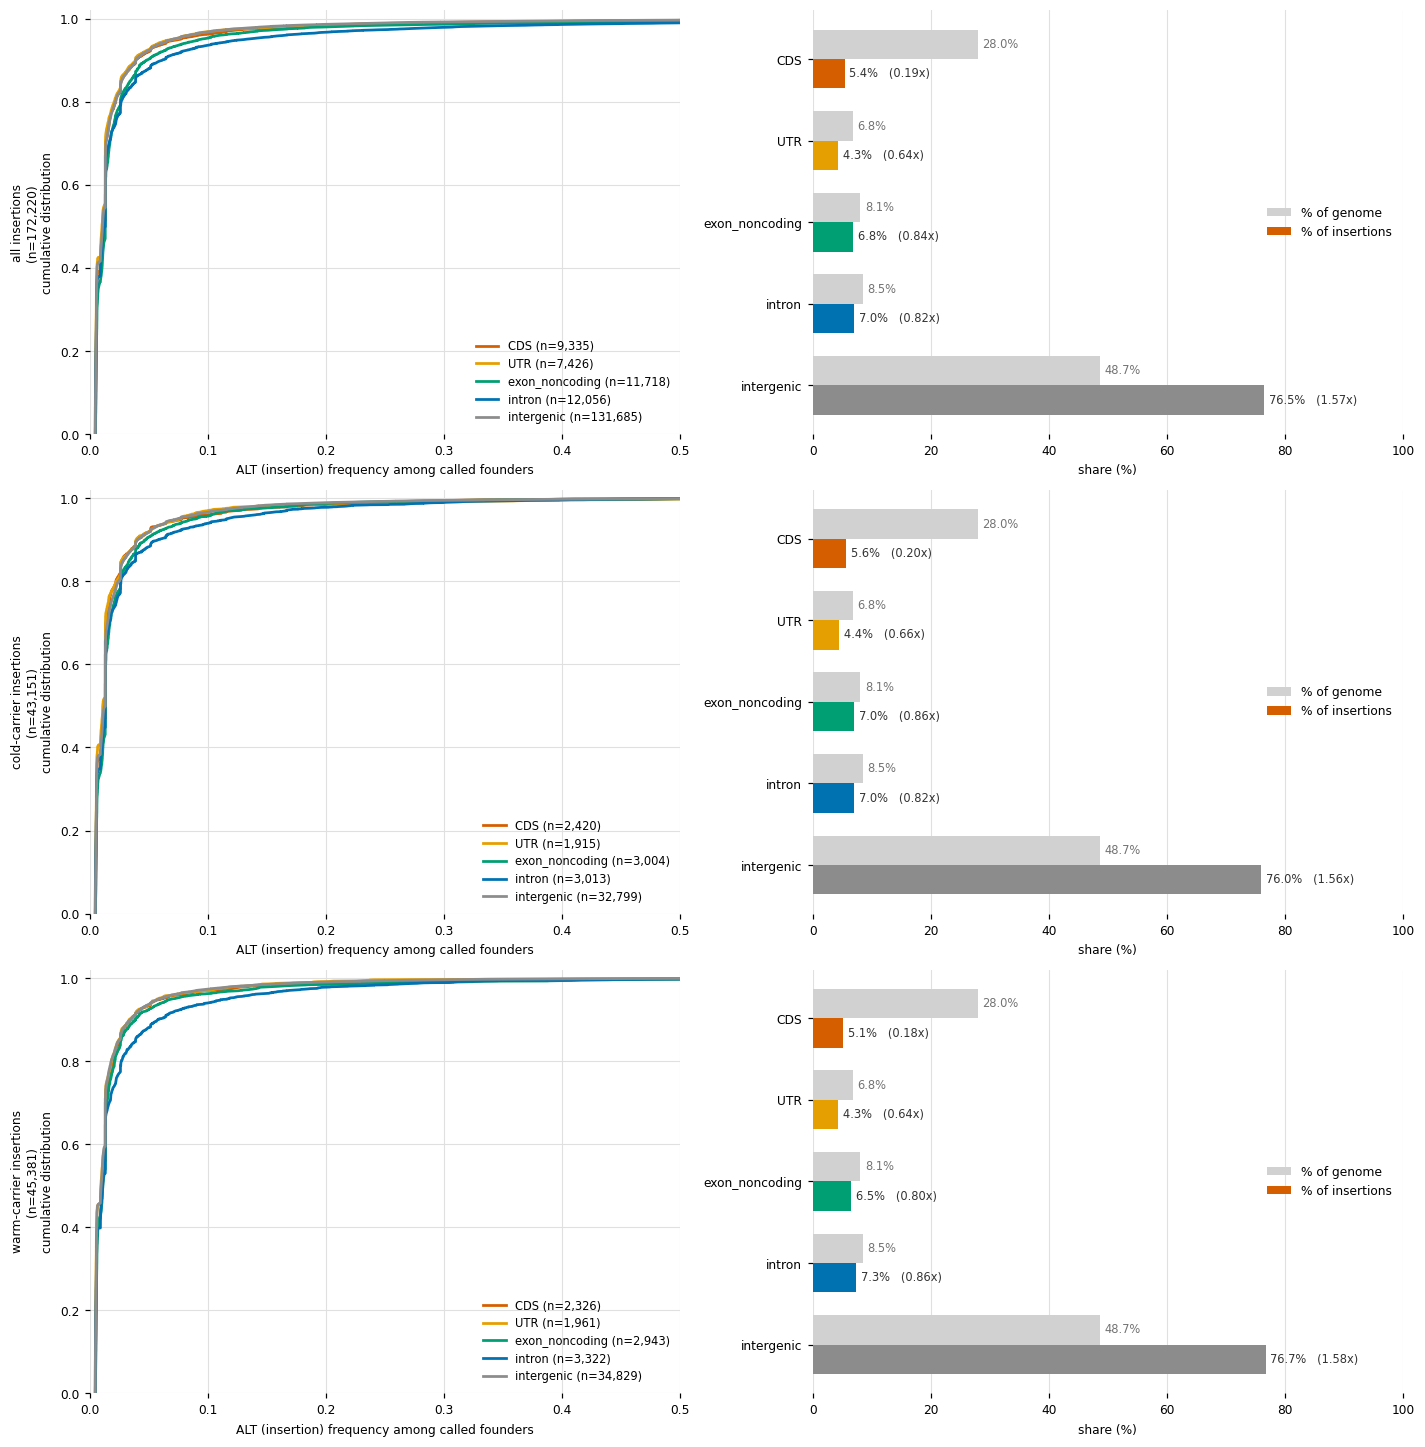

columns: [1] all insertions | [2] cold-carrier insertions | [3] warm-carrier insertions
class           genome %         [1] n      %  ratio         [2] n      %  ratio         [3] n      %  ratio
CDS                 28.0         9,335   5.4%  0.19x         2,420   5.6%  0.20x         2,326   5.1%  0.18x
UTR                  6.8         7,426   4.3%  0.64x         1,915   4.4%  0.66x         1,961   4.3%  0.64x
exon_noncoding       8.1        11,718   6.8%  0.84x         3,004   7.0%  0.86x         2,943   6.5%  0.80x
intron               8.5        12,056   7.0%  0.82x         3,013   7.0%  0.82x         3,322   7.3%  0.86x
intergenic          48.7       131,685  76.5%  1.57x        32,799  76.0%  1.56x        34,829  76.7%  1.58x



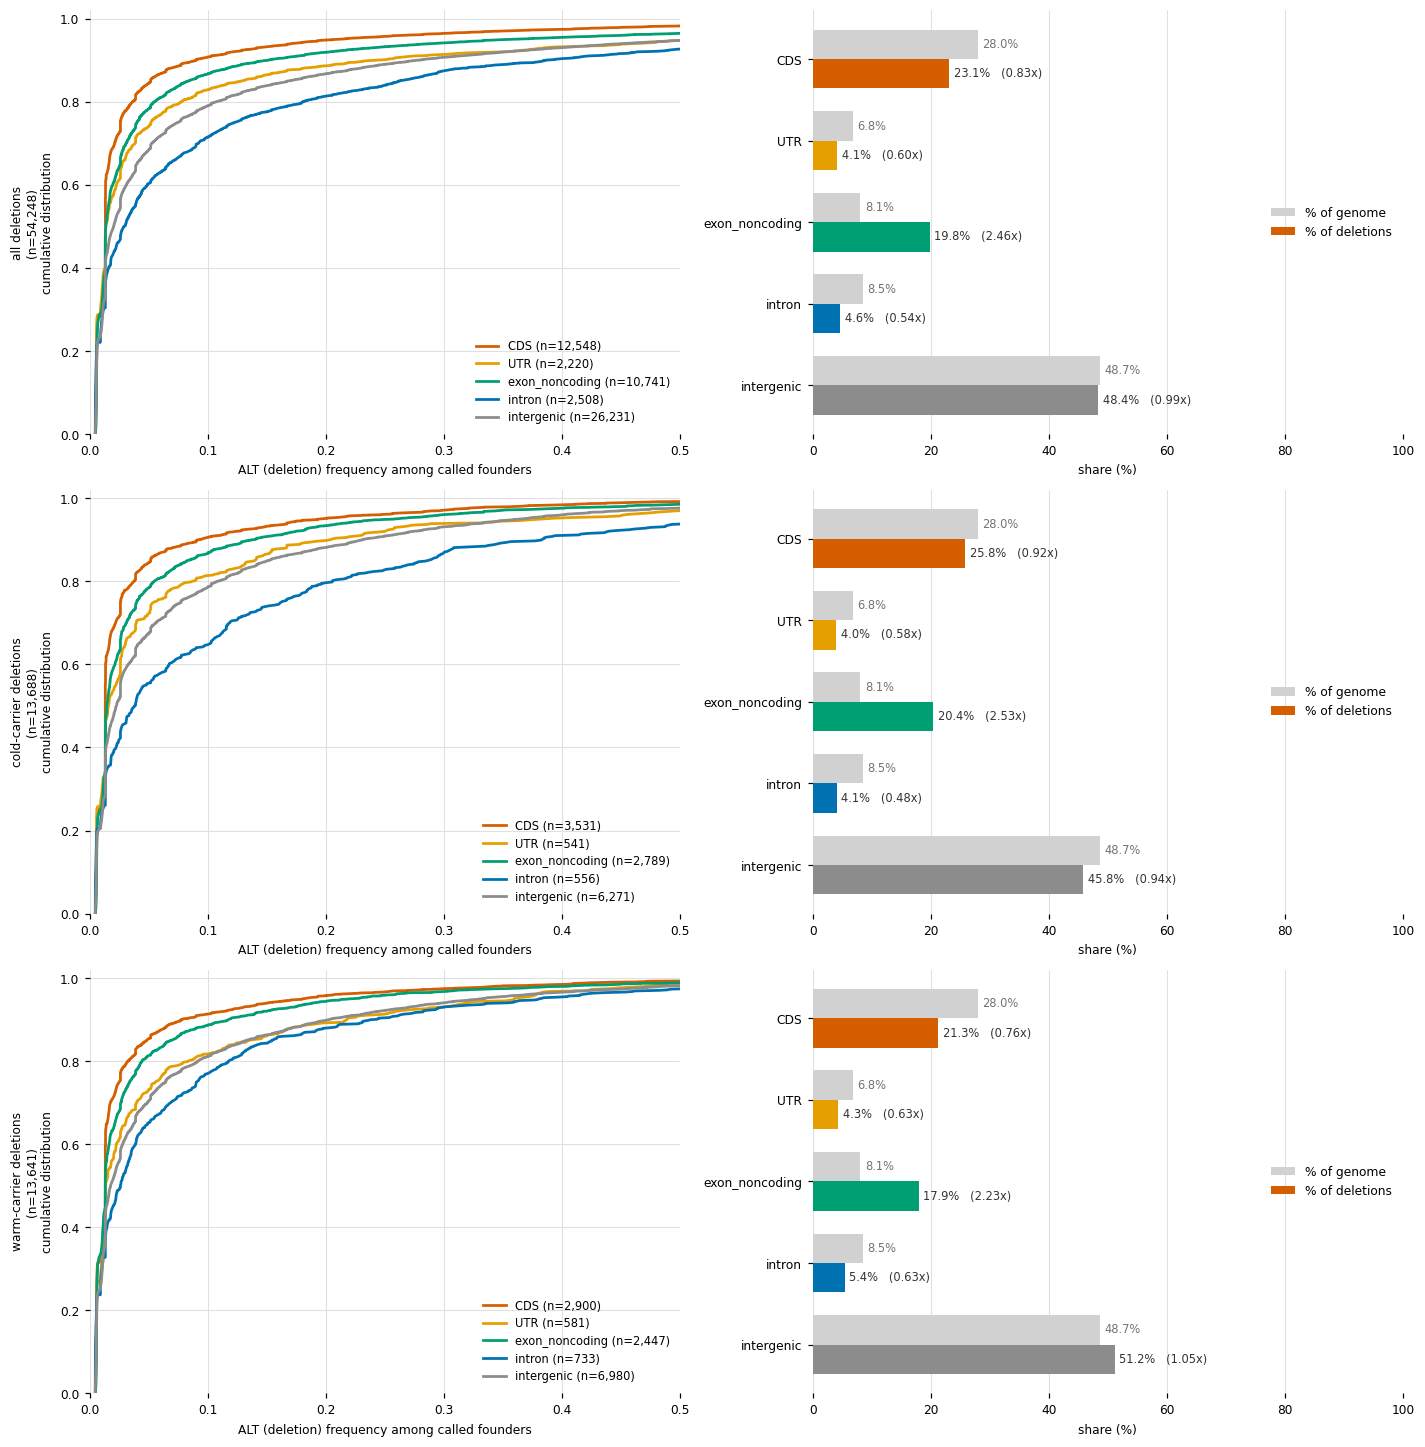

columns: [1] all deletions | [2] cold-carrier deletions | [3] warm-carrier deletions
class           genome %         [1] n      %  ratio         [2] n      %  ratio         [3] n      %  ratio
CDS                 28.0        12,548  23.1%  0.83x         3,531  25.8%  0.92x         2,900  21.3%  0.76x
UTR                  6.8         2,220   4.1%  0.60x           541   4.0%  0.58x           581   4.3%  0.63x
exon_noncoding       8.1        10,741  19.8%  2.46x         2,789  20.4%  2.53x         2,447  17.9%  2.23x
intron               8.5         2,508   4.6%  0.54x           556   4.1%  0.48x           733   5.4%  0.63x
intergenic          48.7        26,231  48.4%  0.99x         6,271  45.8%  0.94x         6,980  51.2%  1.05x

cold vs warm, within each carrier-count stratum (the like-for-like comparison):
  insertions n_alt     n cold  n warm  CDS cold  CDS warm  genic cold  genic warm  TE cold  TE warm
             1         24,838  27,068      5.9%      5.0%       24.4%       22.5

  deletions, CDS-overlap cold minus warm within stratum x size-quintile cells: >0 in 20/25 cells, weighted mean +1.9 pp (unmatched: +4.5 pp)


In [5]:

STRATA=[(1,1),(2,3),(4,7),(8,20),(21,10**6)]
def carrier_groups(D):
    g=pd.Series("mid",index=D.index)
    for a,b in STRATA:
        sel=(D.n_alt>=a)&(D.n_alt<=b)
        q=D.loc[sel,"carrier_bio1"].quantile([.25,.75])
        g[sel]=np.where(D.loc[sel,"carrier_bio1"]<=q.iloc[0],"cold",np.where(D.loc[sel,"carrier_bio1"]>=q.iloc[1],"warm","mid"))
    return g
ALL["cgrp"]=carrier_groups(ALL); DEL["cgrp"]=carrier_groups(DEL)
IC,IW=ALL[ALL.cgrp=="cold"],ALL[ALL.cgrp=="warm"]
DC,DW=DEL[DEL.cgrp=="cold"],DEL[DEL.cgrp=="warm"]
for nm,c,w in (("insertions",IC,IW),("deletions",DC,DW)):
    print(f"{nm}: cold-carrier n={len(c):,} (median carrier bio1 {c.carrier_bio1.median():.1f} C, median freq {c.freq.median():.4f}) | "
          f"warm-carrier n={len(w):,} ({w.carrier_bio1.median():.1f} C, freq {w.freq.median():.4f})")

block([(ALL,"all insertions\n(n=%s)"%f"{len(ALL):,}"),
       (IC,"cold-carrier insertions\n(n=%s)"%f"{len(IC):,}"),
       (IW,"warm-carrier insertions\n(n=%s)"%f"{len(IW):,}")],
      "insertion","ins_spectrum_share_by_carrier_climate.png")
print()
block([(DEL,"all deletions\n(n=%s)"%f"{len(DEL):,}"),
       (DC,"cold-carrier deletions\n(n=%s)"%f"{len(DC):,}"),
       (DW,"warm-carrier deletions\n(n=%s)"%f"{len(DW):,}")],
      "deletion","del_spectrum_share_by_carrier_climate.png")

print("\ncold vs warm, within each carrier-count stratum (the like-for-like comparison):")
labs=[f"{a}" if a==b else (f"{a}-{b}" if b<10**5 else f"{a}+") for a,b in STRATA]
for nm,T in (("insertions",ALL),("deletions",DEL)):
    print(f"  {nm:<11}{'n_alt':<8}{'n cold':>8}{'n warm':>8}{'CDS cold':>10}{'CDS warm':>10}{'genic cold':>12}{'genic warm':>12}{'TE cold':>9}{'TE warm':>9}")
    for (a,b),l in zip(STRATA,labs):
        s=T[(T.n_alt>=a)&(T.n_alt<=b)]; c=s[s.cgrp=="cold"]; w=s[s.cgrp=="warm"]
        print(f"  {'':<11}{l:<8}{len(c):>8,}{len(w):>8,}{100*(c.genic=='CDS').mean():>9.1f}%{100*(w.genic=='CDS').mean():>9.1f}%"
              f"{100*(c.genic!='intergenic').mean():>11.1f}%{100*(w.genic!='intergenic').mean():>11.1f}%{100*c.te_overlap.mean():>8.1f}%{100*w.te_overlap.mean():>8.1f}%")

print("\nSIZE CHECK -- cold-carrier SVs are longer, and overlap probability grows with length:")
print(f"  {'':<11}{'n_alt':<8}{'ins size cold':>14}{'ins size warm':>14}{'del size cold':>14}{'del size warm':>14}{'del midCDS cold':>16}{'del midCDS warm':>16}")
for (a,b),l in zip(STRATA,labs):
    si=ALL[(ALL.n_alt>=a)&(ALL.n_alt<=b)]; sd=DEL[(DEL.n_alt>=a)&(DEL.n_alt<=b)]
    ic,iw=si[si.cgrp=="cold"],si[si.cgrp=="warm"]; dc,dw=sd[sd.cgrp=="cold"],sd[sd.cgrp=="warm"]
    print(f"  {'':<11}{l:<8}{ic['size'].median():>13,.0f} {iw['size'].median():>13,.0f} {dc['size'].median():>13,.0f} {dw['size'].median():>13,.0f} "
          f"{100*(dc.genic_mid=='CDS').mean():>15.1f}%{100*(dw.genic_mid=='CDS').mean():>15.1f}%")
DEL["szq"]=pd.qcut(DEL['size'],5,labels=False); cells=[]
for a,b in STRATA:
    for q in range(5):
        s=DEL[(DEL.n_alt>=a)&(DEL.n_alt<=b)&(DEL.szq==q)]; c=s[s.cgrp=="cold"]; w=s[s.cgrp=="warm"]
        if len(c)>50 and len(w)>50: cells.append(((c.genic=='CDS').mean()-(w.genic=='CDS').mean(),len(c)+len(w)))
cells=np.array(cells)
print(f"  deletions, CDS-overlap cold minus warm within stratum x size-quintile cells: >0 in {(cells[:,0]>0).sum()}/{len(cells)} cells, "
      f"weighted mean {100*np.average(cells[:,0],weights=cells[:,1]):+.1f} pp (unmatched: {100*((DC.genic=='CDS').mean()-(DW.genic=='CDS').mean()):+.1f} pp)")


## 1. Where the purged insertions land

Landing class of the flagged insertions against the unflagged tested insertions (left), and the
log2 ratio per class with a 95% bootstrap interval (right). Selection against the insertion itself
would put CDS above zero.

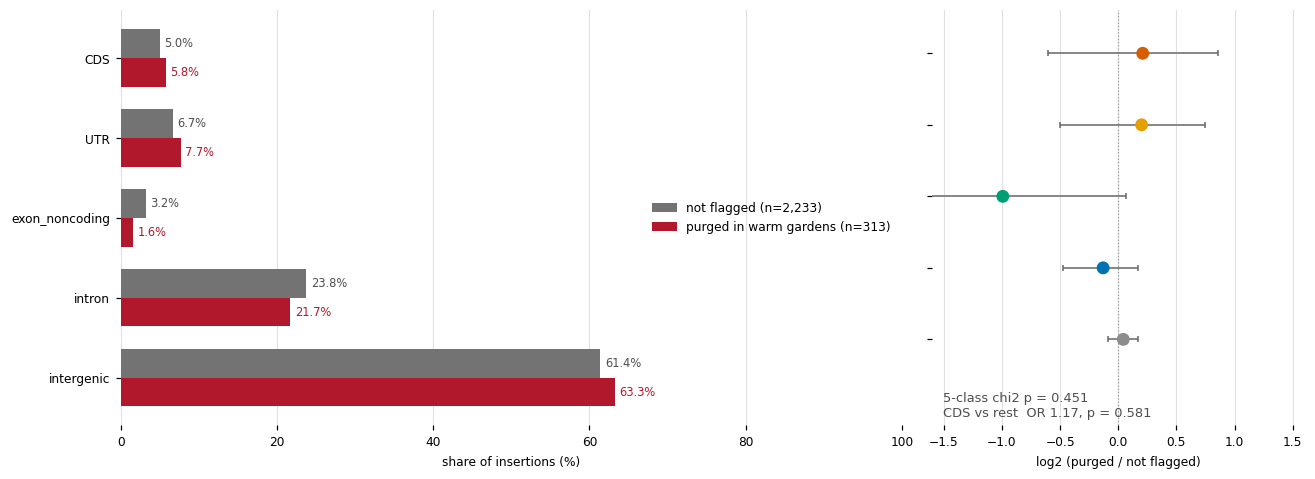

In [6]:

rng=np.random.default_rng(0)
def shares(df): return df.genic.value_counts(normalize=True).reindex(CLS).fillna(0).values*100
a,b=F.genic.values,R.genic.values
draws=np.empty((2000,len(CLS)))
for i in range(2000):
    qa=pd.Series(rng.choice(a,a.size)).value_counts(normalize=True).reindex(CLS).fillna(0).values
    qb=pd.Series(rng.choice(b,b.size)).value_counts(normalize=True).reindex(CLS).fillna(0).values
    draws[i]=np.log2(np.maximum(qa,1e-9)/np.maximum(qb,1e-9))
lfc=np.log2(shares(F)/shares(R)); ci=np.percentile(draws,[2.5,97.5],axis=0)

fig,ax=plt.subplots(1,2,figsize=(12,4.4),gridspec_kw=dict(width_ratios=[2.1,1]))
style(ax[0],axis="x"); style(ax[1],axis="x")
yy=np.arange(len(CLS))[::-1]; h=0.36
ax[0].barh(yy+h/2,shares(R),height=h,color=REST,linewidth=0,label=f"not flagged (n={len(R):,})")
ax[0].barh(yy-h/2,shares(F),height=h,color=FLAG,linewidth=0,label=f"purged in warm gardens (n={len(F)})")
for y,vr,vf in zip(yy,shares(R),shares(F)):
    ax[0].annotate(f"{vr:.1f}%",(vr,y+h/2),xytext=(3,0),textcoords="offset points",va="center",fontsize=7.5,color="0.3")
    ax[0].annotate(f"{vf:.1f}%",(vf,y-h/2),xytext=(3,0),textcoords="offset points",va="center",fontsize=7.5,color=FLAG)
ax[0].set_yticks(yy); ax[0].set_yticklabels(CLS); ax[0].set_xlim(0,100); ax[0].set_xlabel("share of insertions (%)")
ax[0].legend(frameon=False,fontsize=8,loc="center right")

ax[1].axvline(0,color="0.6",ls=":",lw=0.8)
ax[1].errorbar(lfc,yy,xerr=[lfc-ci[0],ci[1]-lfc],fmt="none",ecolor="0.4",elinewidth=1,capsize=2)
ax[1].scatter(lfc,yy,color=[CCOL[c] for c in CLS],s=55,zorder=3)
ax[1].set_yticks(yy); ax[1].set_yticklabels([]); ax[1].set_xlim(-1.6,1.6); ax[1].set_ylim(yy.min()-1.2,yy.max()+0.6)
ax[1].set_xlabel("log2 (purged / not flagged)")
tab=pd.crosstab(J.genic,J.flagA).reindex(CLS)
chi=stats.chi2_contingency(tab.values)[1]
cds=stats.fisher_exact([[tab.loc["CDS",True],tab[True].sum()-tab.loc["CDS",True]],[tab.loc["CDS",False],tab[False].sum()-tab.loc["CDS",False]]])
stat(ax[1],f"5-class chi2 p = {pfmt(chi)}\nCDS vs rest  OR {cds[0]:.2f}, p = {pfmt(cds[1])}",loc=(0.03,0.02))
fig.tight_layout(); fig.savefig(f"{G}/plots/ins_landing_purged_vs_rest.png",dpi=130,bbox_inches="tight"); plt.show()


## 2. What does separate them: the origin climate of the founders that carry them

Mean origin bio1 of the founders carrying each insertion, purged vs not. Because a rare insertion's
carrier mean is close to a single founder's origin while a common one regresses to the panel mean,
the same comparison is repeated within p0 quartiles.

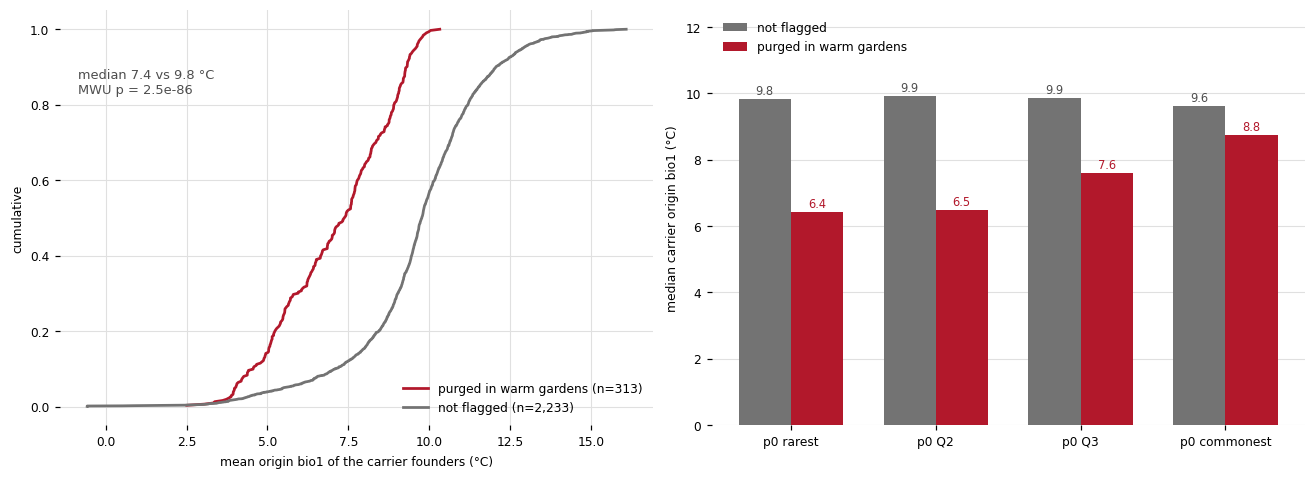

In [7]:

fig,ax=plt.subplots(1,2,figsize=(12,4.4))
style(ax[0]); style(ax[1],axis="y")
for d,c,lab in ((F,FLAG,f"purged in warm gardens (n={len(F)})"),(R,REST,f"not flagged (n={len(R):,})")):
    v=np.sort(d.carrier_bio1.values); ax[0].plot(v,np.arange(1,v.size+1)/v.size,color=c,lw=1.8,label=lab)
ax[0].set_xlabel("mean origin bio1 of the carrier founders (°C)"); ax[0].set_ylabel("cumulative")
ax[0].legend(frameon=False,fontsize=8,loc="lower right")
mw=stats.mannwhitneyu(F.carrier_bio1,R.carrier_bio1)
stat(ax[0],f"median {F.carrier_bio1.median():.1f} vs {R.carrier_bio1.median():.1f} °C\nMWU p = {pfmt(mw.pvalue)}",loc=(0.03,0.80))

J["p0q"]=pd.qcut(J.p0,4,labels=["rarest","Q2","Q3","commonest"])
g=J.groupby(["p0q","flagA"],observed=True).carrier_bio1.median().unstack()
x=np.arange(4); w=0.36
ax[1].bar(x-w/2,g[False],width=w,color=REST,linewidth=0,label="not flagged")
ax[1].bar(x+w/2,g[True],width=w,color=FLAG,linewidth=0,label="purged in warm gardens")
for i,(r_,f_) in enumerate(zip(g[False],g[True])):
    ax[1].annotate(f"{r_:.1f}",(i-w/2,r_),xytext=(0,3),textcoords="offset points",ha="center",fontsize=7.5,color="0.3")
    ax[1].annotate(f"{f_:.1f}",(i+w/2,f_),xytext=(0,3),textcoords="offset points",ha="center",fontsize=7.5,color=FLAG)
ax[1].set_xticks(x); ax[1].set_xticklabels([f"p0 {q}" for q in g.index]); ax[1].set_ylim(0,12.5)
ax[1].set_ylabel("median carrier origin bio1 (°C)"); ax[1].legend(frameon=False,fontsize=8,loc="upper left")
fig.tight_layout(); fig.savefig(f"{G}/plots/ins_purged_carrier_origin.png",dpi=130,bbox_inches="tight"); plt.show()


## Supporting checks (numbers only)

In [8]:

B=J.flagB
print(f"Alternative flag B: s below matched-SNP 10th pct in >= {P['min_hot']} of {len(P['hot_sites'])} hot gardens -> {B.sum()} insertions; "
      f"overlap with A = {(J.flagA&B).sum()} (independence ~{J.flagA.sum()*B.sum()/len(J):.0f}). "
      f"Same rule at {len(P['cold_sites'])} cold gardens flags {(J.n_cold_low>=P['min_hot']).sum()}: per-site s is shared across gardens through carriers, so A is the climate-differential definition.")
tabB=pd.crosstab(J.genic,B).reindex(CLS)
print(f"Under B: CDS {100*tabB.loc['CDS',True]/tabB[True].sum():.1f}% flagged vs {100*tabB.loc['CDS',False]/tabB[False].sum():.1f}% rest; "
      f"genic-vs-intergenic OR {stats.fisher_exact([[tabB[True].sum()-tabB.loc['intergenic',True],tabB.loc['intergenic',True]],[tabB[False].sum()-tabB.loc['intergenic',False],tabB.loc['intergenic',False]]])[0]:.2f} (purged set slightly MORE intergenic).")
print(f"\nOther properties, A flagged vs rest: TE-overlap at site {100*F.te_overlap.mean():.1f}% vs {100*R.te_overlap.mean():.1f}% "
      f"(Fisher p={pfmt(stats.fisher_exact([[F.te_overlap.sum(),(~F.te_overlap).sum()],[R.te_overlap.sum(),(~R.te_overlap).sum()]])[1])}); "
      f"median size {F['size'].median():.0f} vs {R['size'].median():.0f} bp; median p0 {F.p0.median():.3f} vs {R.p0.median():.3f}.")
print(f"\nNo-threshold check, beta(bio1) percentile among matched SNPs by class (0.5 = SNP-like):")
for c in CLS:
    v=J.loc[J.genic==c,'pct_beta1']; print(f"  {c:<15} n={v.size:>5}  mean {v.mean():.3f}")
print(f"  CDS vs intergenic MWU p = {pfmt(stats.mannwhitneyu(J.loc[J.genic=='CDS','pct_beta1'],J.loc[J.genic=='intergenic','pct_beta1']).pvalue)}")
print(f"\nThe tested set is a survivor set: intron {100*(J.genic=='intron').mean():.1f}% vs {100*(ALL.genic=='intron').mean():.1f}% of all 172k; "
      f"TE-overlap {100*J.te_overlap.mean():.1f}% vs {100*ALL.te_overlap.mean():.1f}%; median size {J['size'].median():.0f} vs {ALL['size'].median():.0f} bp.")


Alternative flag B: s below matched-SNP 10th pct in >= 3 of 7 hot gardens -> 377 insertions; overlap with A = 177 (independence ~46). Same rule at 12 cold gardens flags 470: per-site s is shared across gardens through carriers, so A is the climate-differential definition.
Under B: CDS 5.3% flagged vs 5.0% rest; genic-vs-intergenic OR 0.72 (purged set slightly MORE intergenic).

Other properties, A flagged vs rest: TE-overlap at site 16.3% vs 12.0% (Fisher p=0.036); median size 122 vs 111 bp; median p0 0.079 vs 0.084.

No-threshold check, beta(bio1) percentile among matched SNPs by class (0.5 = SNP-like):
  CDS             n=  129  mean 0.416
  UTR             n=  173  mean 0.450
  exon_noncoding  n=   76  mean 0.435
  intron          n=  599  mean 0.464
  intergenic      n= 1569  mean 0.420
  CDS vs intergenic MWU p = 0.776

The tested set is a survivor set: intron 23.5% vs 7.0% of all 172k; TE-overlap 12.6% vs 30.4%; median size 112 vs 754 bp.


## Summary

The insertions purged in warm gardens land where every other common insertion lands — ~5% CDS,
~63% intergenic, no genic enrichment (CDS OR 1.17, p = 0.58). What sets them apart is the founders
that carry them: cold-origin ecotypes (median carrier origin 7.4 vs 9.8 °C, holding within every
p0 quartile). This is the per-variant face of `sv_founder_confound.ipynb`: the gardens remove
cold-origin genotypes and their insertions go with them, regardless of where those insertions sit.

Caveats: only 18 CDS insertions are flagged, so enrichment below ~2× is undetectable; and the
tested set is the common survivors (MAC ≥ 12), not the rare tail where the panel's CDS depletion
lives.